In [1]:
import pandas as pd
import numpy as np
import re
import string
import nltk
import random
import warnings

import matplotlib.pyplot as plt
import seaborn as sns

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from IPython.display import display, HTML, clear_output
import ipywidgets as widgets

warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
data = {

    "query": [

        # 1. General Diabetes Information
        "What is diabetes?",
        "Can you explain diabetes in simple words?",
        "Tell me about the condition called diabetes.",
        "Why is diabetes considered a chronic disease?",
        "What happens inside the body when someone has diabetes?",

        # 2. Types and Causes
        "What are the different types of diabetes?",
        "What is the difference between type 1 and type 2 diabetes?",
        "What causes type 2 diabetes?",
        "Can diabetes develop because of genetics?",
        "Why does the body become resistant to insulin?",

        # 3. Symptoms
        "What are the common symptoms of diabetes?",
        "Why do diabetic patients feel thirsty frequently?",
        "Can frequent urination indicate diabetes?",
        "Does diabetes cause unexplained weight loss?",
        "Why do people with diabetes experience fatigue?",

        # 4. Risk Factors
        "Who is at a higher risk of developing diabetes?",
        "Does obesity increase the risk of diabetes?",
        "Can family history increase diabetes risk?",
        "Does lack of physical activity contribute to diabetes?",
        "How does age affect the chances of developing diabetes?",

        # 5. Blood Glucose Monitoring
        "How can I monitor my blood sugar levels?",
        "What is a glucometer used for?",
        "When should blood glucose levels be checked?",
        "How does a continuous glucose monitor work?",
        "Why is regular blood sugar monitoring important?",

        # 6. Diagnostic Tests
        "Which tests are used to diagnose diabetes?",
        "What is an HbA1c test?",
        "How does a fasting blood sugar test work?",
        "What does an oral glucose tolerance test measure?",
        "How do doctors determine whether someone has diabetes?",

        # 7. Medication Information
        "What medicines are commonly prescribed for diabetes?",
        "What is the purpose of insulin therapy?",
        "How does metformin help manage type 2 diabetes?",
        "Why do some diabetic patients require insulin injections?",
        "What is the difference between insulin and oral diabetes medicines?",

        # 8. Diet and Lifestyle
        "What foods should people with diabetes include in their diet?",
        "Is regular exercise helpful for managing diabetes?",
        "Why should diabetic patients limit sugary drinks?",
        "What is a balanced diet for someone with diabetes?",
        "How can lifestyle changes help control blood sugar?",

        # 9. Emergency Conditions
        "What are the warning signs of dangerously low blood sugar?",
        "What should someone do if their blood sugar drops suddenly?",
        "What are the symptoms of severe hyperglycemia?",
        "Can low blood sugar cause unconsciousness?",
        "When does a diabetic patient need emergency medical help?",

        # 10. Complications
        "What complications can develop due to diabetes?",
        "How does diabetes affect kidney health?",
        "Can diabetes damage the eyes?",
        "Why can diabetes cause nerve damage?",
        "How does uncontrolled diabetes affect heart health?"

    ],

    "intent": [

        "general_information"] * 5 +

        ["types_and_causes"] * 5 +

        ["symptoms"] * 5 +

        ["risk_factors"] * 5 +

        ["glucose_monitoring"] * 5 +

        ["diagnostic_tests"] * 5 +

        ["medication_information"] * 5 +

        ["diet_and_lifestyle"] * 5 +

        ["emergency_conditions"] * 5 +

        ["complications"] * 5
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
print("Total queries:", len(df))

display(df.head(10))

Dataset created successfully!
Total queries: 50


,query,intent
0,What is diabetes?,general_information
1,Can you explain diabetes in simple words?,general_information
2,Tell me about the condition called diabetes.,general_information
3,Why is diabetes considered a chronic disease?,general_information
4,What happens inside the body when someone has ...,general_information
5,What are the different types of diabetes?,types_and_causes
6,What is the difference between type 1 and type...,types_and_causes
7,What causes type 2 diabetes?,types_and_causes
8,Can diabetes develop because of genetics?,types_and_causes
9,Why does the body become resistant to insulin?,types_and_causes


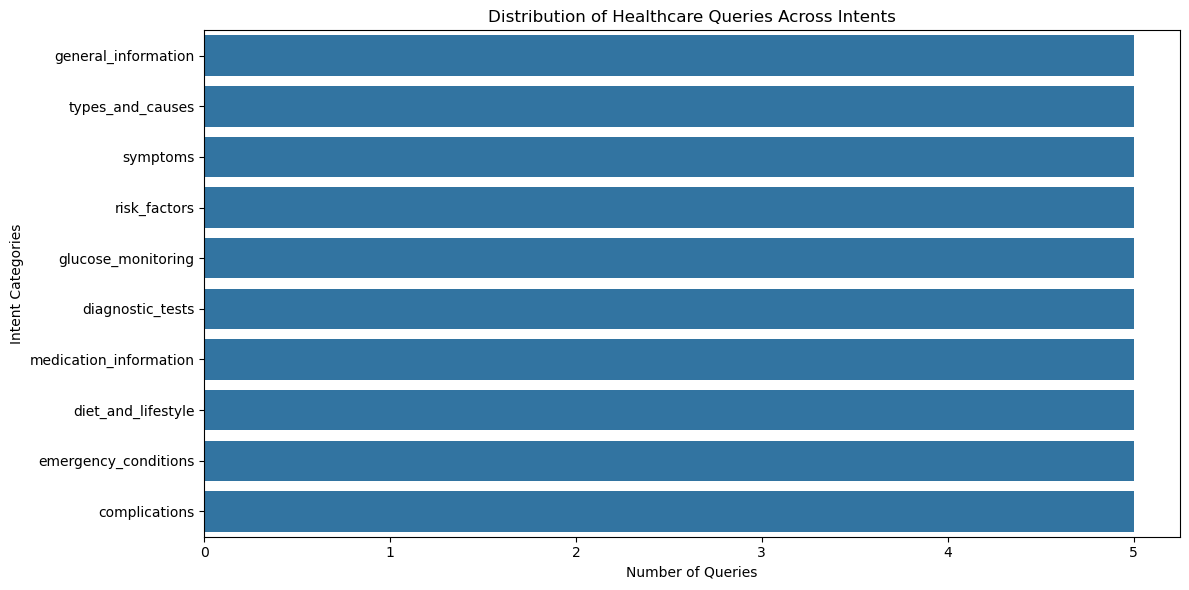

In [3]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y='intent',
    order=df['intent'].value_counts().index
)

plt.title("Distribution of Healthcare Queries Across Intents")
plt.xlabel("Number of Queries")
plt.ylabel("Intent Categories")

plt.tight_layout()
plt.show()

In [4]:
taxonomy = {

    "Diabetes Fundamentals": {

        "General Information": "general_information",

        "Types and Causes": "types_and_causes"

    },

    "Symptoms and Risk Assessment": {

        "Common Symptoms": "symptoms",

        "Risk Factors": "risk_factors"

    },

    "Diagnosis and Monitoring": {

        "Blood Glucose Monitoring": "glucose_monitoring",

        "Diagnostic Tests": "diagnostic_tests"

    },

    "Treatment and Management": {

        "Medication Information": "medication_information",

        "Diet and Lifestyle": "diet_and_lifestyle"

    },

    "Complications and Emergency Care": {

        "Emergency Conditions": "emergency_conditions",

        "Long-term Complications": "complications"

    }

}

print("HIERARCHICAL INTENT TAXONOMY")
print("=" * 40)

for main_category, subcategories in taxonomy.items():

    print("\n" + main_category)

    for subcategory, intent in subcategories.items():

        print("   |--", subcategory, ":", intent)

HIERARCHICAL INTENT TAXONOMY

Diabetes Fundamentals
   |-- General Information : general_information
   |-- Types and Causes : types_and_causes

Symptoms and Risk Assessment
   |-- Common Symptoms : symptoms
   |-- Risk Factors : risk_factors

Diagnosis and Monitoring
   |-- Blood Glucose Monitoring : glucose_monitoring
   |-- Diagnostic Tests : diagnostic_tests

Treatment and Management
   |-- Medication Information : medication_information
   |-- Diet and Lifestyle : diet_and_lifestyle

Complications and Emergency Care
   |-- Emergency Conditions : emergency_conditions
   |-- Long-term Complications : complications


In [5]:
domain_concepts = {

    "Diabetes": "A chronic metabolic condition involving elevated blood glucose.",

    "Insulin": "A hormone that helps glucose enter body cells.",

    "Blood_Glucose": "The amount of glucose present in the bloodstream.",

    "Pancreas": "An organ responsible for producing insulin.",

    "Symptoms": "Physical or clinical signs associated with diabetes.",

    "Risk_Factors": "Conditions or behaviours that increase diabetes risk.",

    "HbA1c": "A blood test reflecting average blood glucose over approximately three months.",

    "Glucometer": "A device used to measure blood glucose levels.",

    "Medication": "Medicines used as part of diabetes management.",

    "Diet": "Food and nutritional choices that influence blood glucose.",

    "Exercise": "Physical activity that can improve glucose management.",

    "Complications": "Health problems that may develop due to diabetes."
}

print("DOMAIN CONCEPTS")
print("=" * 40)

for concept, description in domain_concepts.items():

    print(f"\n{concept}: {description}")

DOMAIN CONCEPTS

Diabetes: A chronic metabolic condition involving elevated blood glucose.

Insulin: A hormone that helps glucose enter body cells.

Blood_Glucose: The amount of glucose present in the bloodstream.

Pancreas: An organ responsible for producing insulin.

Symptoms: Physical or clinical signs associated with diabetes.

Risk_Factors: Conditions or behaviours that increase diabetes risk.

HbA1c: A blood test reflecting average blood glucose over approximately three months.

Glucometer: A device used to measure blood glucose levels.

Medication: Medicines used as part of diabetes management.

Diet: Food and nutritional choices that influence blood glucose.

Exercise: Physical activity that can improve glucose management.

Complications: Health problems that may develop due to diabetes.


In [6]:
ontology_relationships = [

    ("Diabetes", "affects", "Blood_Glucose"),

    ("Pancreas", "produces", "Insulin"),

    ("Insulin", "regulates", "Blood_Glucose"),

    ("Diabetes", "may_cause", "Symptoms"),

    ("Risk_Factors", "increase_likelihood_of", "Diabetes"),

    ("HbA1c", "measures", "Blood_Glucose"),

    ("Glucometer", "monitors", "Blood_Glucose"),

    ("Medication", "helps_manage", "Diabetes"),

    ("Diet", "influences", "Blood_Glucose"),

    ("Exercise", "helps_regulate", "Blood_Glucose"),

    ("Diabetes", "may_lead_to", "Complications"),

    ("Insulin", "is_used_in_treatment_of", "Diabetes"),

    ("Blood_Glucose", "is_monitored_using", "Glucometer"),

    ("HbA1c", "supports_diagnosis_of", "Diabetes")

]

print("ONTOLOGY RELATIONSHIPS")
print("=" * 40)

for source, relation, target in ontology_relationships:

    print(f"{source} --{relation}--> {target}")

print("\nTotal Concepts:", len(domain_concepts))
print("Total Relationships:", len(ontology_relationships))

ONTOLOGY RELATIONSHIPS
Diabetes --affects--> Blood_Glucose
Pancreas --produces--> Insulin
Insulin --regulates--> Blood_Glucose
Diabetes --may_cause--> Symptoms
Risk_Factors --increase_likelihood_of--> Diabetes
HbA1c --measures--> Blood_Glucose
Glucometer --monitors--> Blood_Glucose
Medication --helps_manage--> Diabetes
Diet --influences--> Blood_Glucose
Exercise --helps_regulate--> Blood_Glucose
Diabetes --may_lead_to--> Complications
Insulin --is_used_in_treatment_of--> Diabetes
Blood_Glucose --is_monitored_using--> Glucometer
HbA1c --supports_diagnosis_of--> Diabetes

Total Concepts: 12
Total Relationships: 14


In [7]:
lemmatizer = WordNetLemmatizer()

stop_words = set(stopwords.words('english'))

# Preserve negation words because they can change medical meaning.
stop_words = stop_words - {'no', 'not', 'nor', 'never'}

print("NLP preprocessing tools initialised!")

NLP preprocessing tools initialised!


In [8]:
def preprocess_text(text):

    text = text.lower()

    # Keep digits so terms such as type 1 and type 2 remain distinct.
    text = re.sub(r'[^a-z0-9\s]', ' ', text)

    tokens = word_tokenize(text)

    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return " ".join(tokens)

In [9]:
sample_text = "What are the COMMON symptoms of Diabetes?"

processed_text = preprocess_text(sample_text)

print("Original Query:")
print(sample_text)

print("\nProcessed Query:")
print(processed_text)

Original Query:
What are the COMMON symptoms of Diabetes?

Processed Query:
common symptom diabetes


In [10]:
df['processed_query'] = df['query'].apply(preprocess_text)

display(df.head(10))

# Extra, human-labeled paraphrases improve coverage without contaminating the test split.
augmentation_data = {
    "general_information": [
        "What does diabetes do to blood sugar levels?",
        "How does insulin help the body use glucose?",
        "Is diabetes a long-term condition?"
    ],
    "types_and_causes": [
        "How are type 1 and type 2 diabetes different?",
        "What is gestational diabetes?",
        "Why does type 2 diabetes develop?"
    ],
    "symptoms": [
        "Do frequent urination and thirst indicate diabetes?",
        "Can diabetes cause blurry eyesight or fatigue?",
        "What are early signs of high blood sugar?"
    ],
    "risk_factors": [
        "Does a parent with diabetes increase my risk?",
        "Can inactivity raise the chance of type 2 diabetes?",
        "Does age affect diabetes risk?"
    ],
    "glucose_monitoring": [
        "How do I use a blood glucose meter?",
        "Can a CGM check sugar all day?",
        "When should I check my blood glucose?"
    ],
    "diagnostic_tests": [
        "How is diabetes diagnosed with an HbA1c?",
        "What fasting blood glucose result indicates diabetes?",
        "What happens during an oral glucose tolerance test?"
    ],
    "medication_information": [
        "Is insulin used to treat diabetes?",
        "What does metformin do for type 2 diabetes?",
        "Which medicines lower blood sugar?",
        "What medications are commonly used to treat diabetes?"
    ],
    "diet_and_lifestyle": [
        "What foods should people with diabetes choose?",
        "Can exercise help manage blood sugar?",
        "Should I limit carbohydrates with diabetes?",
        "What foods should a person with diabetes eat?",
        "What meals are suitable for diabetic patients?",
        "How can diet help control diabetes?"
    ],
    "emergency_conditions": [
        "What should I do for severe low blood sugar?",
        "Can very high blood sugar cause confusion or vomiting?",
        "When is hypoglycemia an emergency?"
    ],
    "complications": [
        "Can long-term diabetes harm the kidneys or eyes?",
        "What nerve problems can diabetes cause?",
        "Does diabetes increase heart disease risk?"
    ]
}

augmentation_queries = [
    query
    for queries in augmentation_data.values()
    for query in queries
]

augmentation_labels = [
    intent
    for intent, queries in augmentation_data.items()
    for _ in queries
]

augmentation_processed_queries = [
    preprocess_text(query)
    for query in augmentation_queries
]

,query,intent,processed_query
0,What is diabetes?,general_information,diabetes
1,Can you explain diabetes in simple words?,general_information,explain diabetes simple word
2,Tell me about the condition called diabetes.,general_information,tell condition called diabetes
3,Why is diabetes considered a chronic disease?,general_information,diabetes considered chronic disease
4,What happens inside the body when someone has ...,general_information,happens inside body someone diabetes
5,What are the different types of diabetes?,types_and_causes,different type diabetes
6,What is the difference between type 1 and type...,types_and_causes,difference type 1 type 2 diabetes
7,What causes type 2 diabetes?,types_and_causes,cause type 2 diabetes
8,Can diabetes develop because of genetics?,types_and_causes,diabetes develop genetics
9,Why does the body become resistant to insulin?,types_and_causes,body become resistant insulin


In [11]:
X = df['processed_query']
y = df['intent']

print("Text data prepared; split before fitting TF-IDF to avoid test leakage.")
print("Total original queries:", len(X))

Text data prepared; split before fitting TF-IDF to avoid test leakage.
Total original queries: 50


In [12]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y

)

print("Training Samples:", X_train.shape[0])

print("Testing Samples:", X_test.shape[0])

Training Samples: 35
Testing Samples: 15


In [13]:
X_train_augmented = pd.concat(
    [
        X_train.reset_index(drop=True),
        pd.Series(augmentation_processed_queries)
    ],
    ignore_index=True
)

y_train_augmented = pd.concat(
    [
        y_train.reset_index(drop=True),
        pd.Series(augmentation_labels)
    ],
    ignore_index=True
)

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=1000,
    sublinear_tf=True,
    token_pattern=r"(?u)\b\w+\b"
)

X_train_vectorized = tfidf.fit_transform(X_train_augmented)
X_test = tfidf.transform(X_test)

model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

model.fit(X_train_vectorized, y_train_augmented)

print("Logistic Regression Model Trained Successfully!")
print("Labeled training paraphrases:", len(augmentation_queries))

Logistic Regression Model Trained Successfully!
Labeled training paraphrases: 34


In [14]:
y_pred = model.predict(X_test)

print("Predictions Generated Successfully!")

results = pd.DataFrame({

    "Actual Intent": y_test.values,

    "Predicted Intent": y_pred

})

display(results)

Predictions Generated Successfully!


,Actual Intent,Predicted Intent
0,emergency_conditions,emergency_conditions
1,diet_and_lifestyle,diet_and_lifestyle
2,medication_information,types_and_causes
3,complications,complications
4,glucose_monitoring,glucose_monitoring
5,general_information,complications
6,general_information,general_information
7,emergency_conditions,glucose_monitoring
8,diet_and_lifestyle,diet_and_lifestyle
9,symptoms,symptoms


In [15]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

print("MODEL EVALUATION")
print("=" * 40)

print(f"Accuracy  : {accuracy:.4f}")

print(f"Precision : {precision:.4f}")

print(f"Recall    : {recall:.4f}")

print(f"F1-Score  : {f1:.4f}")

MODEL EVALUATION
Accuracy  : 0.6667
Precision : 0.6667
Recall    : 0.6667
F1-Score  : 0.6267


In [16]:
print("CLASSIFICATION REPORT")
print("=" * 50)

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

CLASSIFICATION REPORT
                        precision    recall  f1-score   support

         complications       0.50      1.00      0.67         1
      diagnostic_tests       0.00      0.00      0.00         1
    diet_and_lifestyle       1.00      1.00      1.00         2
  emergency_conditions       1.00      0.50      0.67         2
   general_information       0.33      0.50      0.40         2
    glucose_monitoring       0.50      1.00      0.67         1
medication_information       1.00      0.50      0.67         2
          risk_factors       0.00      0.00      0.00         1
              symptoms       1.00      1.00      1.00         1
      types_and_causes       0.67      1.00      0.80         2

              accuracy                           0.67        15
             macro avg       0.60      0.65      0.59        15
          weighted avg       0.67      0.67      0.63        15



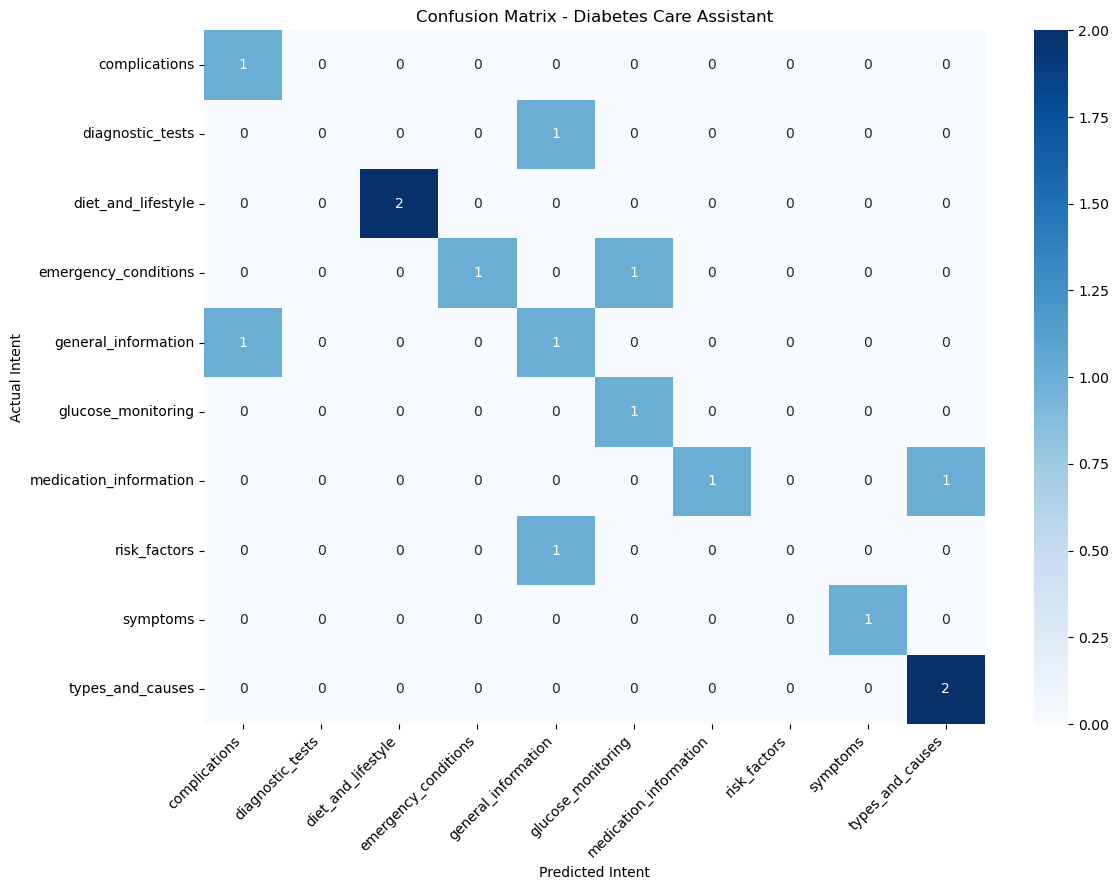

Final chatbot model trained on all labeled examples: 84


In [17]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(12, 9))

sns.heatmap(

    cm,

    annot=True,

    fmt='d',

    cmap='Blues',

    xticklabels=model.classes_,

    yticklabels=model.classes_

)

plt.title("Confusion Matrix - Diabetes Care Assistant")

plt.xlabel("Predicted Intent")

plt.ylabel("Actual Intent")

plt.xticks(rotation=45, ha='right')

plt.yticks(rotation=0)

plt.tight_layout()

plt.show()

# Refit on all original examples after evaluation for the deployed chatbot.
final_training_queries = pd.concat(
    [
        df['processed_query'].reset_index(drop=True),
        pd.Series(augmentation_processed_queries)
    ],
    ignore_index=True
)

final_training_labels = pd.concat(
    [
        y.reset_index(drop=True),
        pd.Series(augmentation_labels)
    ],
    ignore_index=True
)

X_final = tfidf.fit_transform(final_training_queries)

model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

model.fit(X_final, final_training_labels)
print("Final chatbot model trained on all labeled examples:", len(final_training_labels))

In [18]:
knowledge_base = {

    "general_information": {

        "title": "Understanding Diabetes",

        "response": """

Diabetes is a chronic health condition that affects how the body
regulates blood glucose (blood sugar).

Glucose is an important source of energy for the body.

Insulin, a hormone produced by the pancreas, helps glucose enter
body cells. Diabetes occurs when the body does not produce enough
insulin or cannot use it effectively.

There are different types of diabetes, including Type 1,
Type 2 and gestational diabetes.

"""

    },

    "types_and_causes": {

        "title": "Types and Causes of Diabetes",

        "response": """

The major types of diabetes include:

1. Type 1 Diabetes:
The immune system attacks insulin-producing cells in the pancreas.

2. Type 2 Diabetes:
The body becomes resistant to insulin or does not produce enough
insulin to maintain normal blood glucose.

3. Gestational Diabetes:
This develops during pregnancy.

Genetic factors, lifestyle and other health conditions may
contribute to diabetes risk, depending on the type.

"""

    },

    "symptoms": {

        "title": "Common Symptoms",

        "response": """

Common symptoms associated with diabetes include:

1. Frequent urination.
2. Increased thirst.
3. Increased hunger.
4. Unexplained weight loss.
5. Fatigue.
6. Blurred vision.
7. Slow-healing wounds.

Some individuals, particularly those with Type 2 diabetes,
may not experience noticeable symptoms.

Consult a healthcare professional if you experience
possible symptoms.

"""

    },

    "risk_factors": {

        "title": "Diabetes Risk Factors",

        "response": """

Several factors can increase the likelihood of developing
Type 2 diabetes.

These include:

1. Family history of diabetes.
2. Excess body weight.
3. Physical inactivity.
4. Increasing age.
5. History of gestational diabetes.
6. Certain metabolic and medical conditions.

Having a risk factor does not necessarily mean that
a person will develop diabetes.

"""

    },

    "glucose_monitoring": {

        "title": "Blood Glucose Monitoring",

        "response": """

Blood glucose monitoring helps individuals understand
how their blood sugar levels change.

Common monitoring methods include:

1. Glucometer:
A device that measures blood glucose using a small blood sample.

2. Continuous Glucose Monitor (CGM):
A wearable device that tracks glucose levels throughout the day.

Monitoring frequency depends on the individual's treatment
plan and healthcare provider's recommendations.

"""

    },

    "diagnostic_tests": {

        "title": "Diabetes Diagnostic Tests",

        "response": """

Healthcare professionals use several tests to diagnose diabetes.

Common tests include:

1. HbA1c Test:
Measures average blood glucose over approximately three months.

2. Fasting Plasma Glucose:
Measures glucose after an overnight fast.

3. Oral Glucose Tolerance Test:
Measures how the body responds to glucose.

For non-pregnant adults, commonly used diagnostic thresholds
include:

HbA1c: 6.5% or higher.
Fasting plasma glucose: 126 mg/dL or higher.
Two-hour glucose tolerance test: 200 mg/dL or higher.

Diagnosis generally requires appropriate confirmation,
unless there is unequivocal hyperglycemia.

A healthcare professional should interpret test results.

"""

    },

    "medication_information": {

        "title": "Diabetes Medication Information",

        "response": """

Diabetes management may involve different types of medication.

Examples include:

1. Insulin:
Used in Type 1 diabetes and sometimes in Type 2 diabetes.

2. Metformin:
A commonly prescribed medicine for Type 2 diabetes.

3. Other glucose-lowering medicines:
These may work through different mechanisms.

Medication choice depends on individual health conditions,
blood glucose levels and medical history.

Never start, stop or modify medication without consulting
a qualified healthcare professional.

"""

    },

    "diet_and_lifestyle": {

        "title": "Diet and Lifestyle Management",

        "response": """

Healthy lifestyle choices can support diabetes management.

Some useful practices include:

1. Eating balanced meals.
2. Including vegetables and fibre-rich foods.
3. Choosing suitable portions of carbohydrates.
4. Limiting sugary beverages.
5. Engaging in regular physical activity.
6. Maintaining a healthy sleep routine.
7. Monitoring blood glucose as advised.

Dietary requirements differ between individuals.

A registered dietitian or healthcare professional can
help create an appropriate meal plan.

"""

    },

    "emergency_conditions": {

        "title": "Diabetes Emergency Information",

        "response": """

Diabetes-related emergencies can involve dangerously low
or dangerously high blood glucose.

Severe hypoglycemia may cause:

1. Confusion.
2. Seizures.
3. Loss of consciousness.

Severe hyperglycemia may be associated with diabetic
ketoacidosis or hyperosmolar hyperglycemic state.

Warning signs can include vomiting, abdominal pain,
difficulty breathing, severe dehydration and confusion.

If someone is unconscious or having a seizure:

- Call emergency medical services immediately.
- Do not give food, water or medication by mouth.
- If breathing, place them in the recovery position if safe.
- Follow emergency professionals' instructions.

Do not delay emergency medical care.

"""

    },

    "complications": {

        "title": "Long-Term Diabetes Complications",

        "response": """

Uncontrolled or prolonged high blood glucose can contribute
to several health complications.

These include:

1. Diabetic Retinopathy:
Damage to blood vessels in the eyes.

2. Diabetic Nephropathy:
Kidney damage associated with diabetes.

3. Diabetic Neuropathy:
Nerve damage that can cause pain, tingling or numbness.

4. Cardiovascular Disease:
Increased risk of heart and blood vessel problems.

Regular medical checkups and appropriate diabetes management
can help reduce the risk of complications.

"""

    }

}

print("Healthcare Knowledge Base Created Successfully!")

print("Total Knowledge Base Categories:", len(knowledge_base))

Healthcare Knowledge Base Created Successfully!
Total Knowledge Base Categories: 10


In [19]:
emergency_keywords = [

    "unconscious",

    "unresponsive",

    "seizure",

    "convulsion",

    "cannot breathe",

    "difficulty breathing",

    "severe confusion",

    "passed out",

    "not waking up",

    "loss of consciousness",

    "diabetic coma"

]

In [20]:
def detect_emergency(query):

    query = query.lower()

    for keyword in emergency_keywords:

        if keyword in query:

            return True

    return False


def is_diabetes_related(query):

    diabetes_keywords = (
        "diabetes",
        "diabetic",
        "blood sugar",
        "blood glucose",
        "glucose",
        "insulin",
        "hba1c",
        "a1c",
        "metformin",
        "hypoglyc",
        "hyperglyc",
        "gestational",
        "type 1",
        "type 2",
        "cgm"
    )

    query = query.lower()

    return any(keyword in query for keyword in diabetes_keywords)

In [21]:
# Softmax scores are modest in a 10-intent model; scope is checked separately.
CONFIDENCE_THRESHOLD = 0.15

def check_confidence(confidence):

    if confidence < CONFIDENCE_THRESHOLD:

        return True

    return False


def unsupported_response():

    return """

I'm sorry, but I currently provide information related
to diabetes care only.

You can ask me about:

- Diabetes basics
- Symptoms and risk factors
- Blood glucose monitoring
- Diagnostic tests
- Diabetes medication information
- Diet and lifestyle
- Complications and emergencies

Please consult an appropriate healthcare professional
for questions outside my scope.

"""

In [22]:
def medication_safety_rule(query):

    medication_words = [

        "medicine",
        "medication",
        "insulin",
        "metformin",
        "dosage",
        "dose",
        "tablet",
        "injection"

    ]

    query = query.lower()

    if any(word in query for word in medication_words):

        return """

MEDICATION SAFETY NOTICE:

Medication selection and dosage must be determined
by a qualified healthcare professional.

Do not independently change, stop or start
your prescribed diabetes medication.

"""

    return ""


def diagnosis_safety_rule(query):

    diagnosis_words = [

        "diagnose",
        "diagnosis",
        "do i have diabetes",
        "am i diabetic",
        "confirm diabetes"

    ]

    query = query.lower()

    if any(word in query for word in diagnosis_words):

        return """

MEDICAL DISCLAIMER:

This assistant cannot diagnose diabetes.

A proper diagnosis requires appropriate medical
evaluation and laboratory testing.

Please consult a qualified healthcare professional.

"""

    return ""

In [23]:
def diabetes_assistant(query):

    query = query.strip()

    if not query:

        return {

            "status": "error",

            "response": "Please enter a healthcare-related question."

        }

    # RULE 1: Emergency detection

    if detect_emergency(query):

        return {

            "status": "EMERGENCY",

            "intent": "emergency_conditions",

            "confidence": 1.0,

            "response": """

🚨 EMERGENCY ALERT

The query contains language associated with a potentially
serious medical emergency.

If someone is unconscious, having a seizure or experiencing
severe breathing difficulty, call emergency medical services
immediately.

Do not give food, drinks or medicines by mouth to someone
who is unconscious.

In India, call 112 for emergency assistance.

This assistant cannot provide emergency treatment.
Do not wait for a chatbot response before seeking help.

"""

        }

    # Reject unrelated questions before the classifier forces an intent.

    if not is_diabetes_related(query):

        return {

            "status": "UNSUPPORTED",

            "response": unsupported_response()

        }

    # NLP PREPROCESSING

    processed_query = preprocess_text(query)

    # TF-IDF TRANSFORMATION

    query_vector = tfidf.transform([processed_query])

    # INTENT CLASSIFICATION

    predicted_intent = model.predict(query_vector)[0]

    # CONFIDENCE CALCULATION

    probabilities = model.predict_proba(query_vector)[0]

    confidence = max(probabilities)

    # RULE 2: Low-confidence handling

    if check_confidence(confidence):

        return {

            "status": "LOW CONFIDENCE",

            "intent": predicted_intent,

            "confidence": confidence,

            "response": """

I'm not sufficiently confident about the meaning of your question.

Could you rephrase it or provide more details?

I am designed to answer questions related to diabetes care.

"""

        }

    # RULE 3: Unsupported-query handling

    if predicted_intent not in knowledge_base:

        return {

            "status": "UNSUPPORTED",

            "response": unsupported_response()

        }

    # KNOWLEDGE RETRIEVAL

    knowledge = knowledge_base[predicted_intent]

    response = knowledge["response"]

    # RULE 4: Medication safety

    medication_notice = medication_safety_rule(query)

    # RULE 5: Diagnosis disclaimer

    diagnosis_notice = diagnosis_safety_rule(query)

    # RULE 6: Normal knowledge retrieval

    final_response = (

        response +

        medication_notice +

        diagnosis_notice

    )

    return {

        "status": "SUCCESS",

        "intent": predicted_intent,

        "confidence": confidence,

        "processed_query": processed_query,

        "response": final_response

    }


print("Diabetes Cognitive Assistant Integrated Successfully!")

Diabetes Cognitive Assistant Integrated Successfully!


In [24]:
test_queries = [

    "What exactly is diabetes?",

    "Explain the causes of different diabetes types.",

    "Why do diabetic people feel thirsty?",

    "Does being overweight increase diabetes risk?",

    "How can I check my glucose at home?",

    "Which laboratory tests identify diabetes?",

    "Tell me about medicines used for diabetes.",

    "What should a diabetic person eat?",

    "What happens when blood sugar becomes dangerously low?",

    "Can diabetes damage the kidneys?"

]

print("INTENT CLASSIFICATION TESTING")
print("=" * 60)

for query in test_queries:

    result = diabetes_assistant(query)

    print("\nUser:", query)

    print("Predicted Intent:", result.get("intent"))

    print("Status:", result["status"])

    print("Confidence:", round(result.get("confidence", 0), 3))

    print("-" * 60)

INTENT CLASSIFICATION TESTING

User: What exactly is diabetes?
Predicted Intent: general_information
Status: SUCCESS
Confidence: 0.227
------------------------------------------------------------

User: Explain the causes of different diabetes types.
Predicted Intent: types_and_causes
Status: SUCCESS
Confidence: 0.201
------------------------------------------------------------

User: Why do diabetic people feel thirsty?
Predicted Intent: symptoms
Status: SUCCESS
Confidence: 0.18
------------------------------------------------------------

User: Does being overweight increase diabetes risk?
Predicted Intent: risk_factors
Status: SUCCESS
Confidence: 0.301
------------------------------------------------------------

User: How can I check my glucose at home?
Predicted Intent: glucose_monitoring
Status: SUCCESS
Confidence: 0.252
------------------------------------------------------------

User: Which laboratory tests identify diabetes?
Predicted Intent: diagnostic_tests
Status: SUCCESS


In [25]:
query = "Why do I keep visiting the washroom and feeling thirsty?"

result = diabetes_assistant(query)

print("User:", query)

print("\nAssistant:", result["response"])

print("\nPredicted Intent:", result.get("intent"))

print("Confidence:", result.get("confidence"))

User: Why do I keep visiting the washroom and feeling thirsty?

Assistant: 

I'm sorry, but I currently provide information related
to diabetes care only.

You can ask me about:

- Diabetes basics
- Symptoms and risk factors
- Blood glucose monitoring
- Diagnostic tests
- Diabetes medication information
- Diet and lifestyle
- Complications and emergencies

Please consult an appropriate healthcare professional
for questions outside my scope.



Predicted Intent: None
Confidence: None


In [26]:
query = "What are the symptoms of dengue fever?"

result = diabetes_assistant(query)

print("User:", query)

print("\nAssistant:", result["response"])

print("\nStatus:", result["status"])

User: What are the symptoms of dengue fever?

Assistant: 

I'm sorry, but I currently provide information related
to diabetes care only.

You can ask me about:

- Diabetes basics
- Symptoms and risk factors
- Blood glucose monitoring
- Diagnostic tests
- Diabetes medication information
- Diet and lifestyle
- Complications and emergencies

Please consult an appropriate healthcare professional
for questions outside my scope.



Status: UNSUPPORTED


In [27]:
query = "What is the capital of France?"

result = diabetes_assistant(query)

print("User:", query)

print("\nAssistant:", result["response"])

print("\nStatus:", result["status"])

print("Confidence:", result.get("confidence"))

User: What is the capital of France?

Assistant: 

I'm sorry, but I currently provide information related
to diabetes care only.

You can ask me about:

- Diabetes basics
- Symptoms and risk factors
- Blood glucose monitoring
- Diagnostic tests
- Diabetes medication information
- Diet and lifestyle
- Complications and emergencies

Please consult an appropriate healthcare professional
for questions outside my scope.



Status: UNSUPPORTED
Confidence: None


In [28]:
query = "My diabetic relative is unconscious and not responding."

result = diabetes_assistant(query)

print("User:", query)

print("\nAssistant:", result["response"])

print("\nStatus:", result["status"])

User: My diabetic relative is unconscious and not responding.

Assistant: 

🚨 EMERGENCY ALERT

The query contains language associated with a potentially
serious medical emergency.

If someone is unconscious, having a seizure or experiencing
severe breathing difficulty, call emergency medical services
immediately.

Do not give food, drinks or medicines by mouth to someone
who is unconscious.

In India, call 112 for emergency assistance.

This assistant cannot provide emergency treatment.
Do not wait for a chatbot response before seeking help.



Status: EMERGENCY


In [29]:
import gradio as gr

def chatbot_response(message, history):
    if not message.strip():
        return "Please enter a question."

    result = diabetes_assistant(message)

    response = result["response"]
    intent = result.get("intent", "Not classified")
    confidence = result.get("confidence", 0)
    status = result["status"]

    final_response = f"""
{response}

----------------------------------

Classification Details

Predicted Intent: {intent}
Confidence Score: {confidence:.3f}
Status: {status}
"""

    return final_response


demo = gr.ChatInterface(
    fn=chatbot_response,
    title="Diabetes Care Information Assistant",
    description="Ask questions about diabetes symptoms, diagnosis, medications, diet, glucose monitoring and complications.",
    examples=[
        "What is diabetes?",
        "What are the common symptoms of diabetes?",
        "How can I monitor my blood sugar?",
        "What foods are suitable for diabetic patients?",
        "What is an HbA1c test?",
        "What are the complications of diabetes?"
    ]
)

demo.launch(
    server_name="127.0.0.1",
    server_port=7860,
    inline=False,
    inbrowser=True,
    share=False
)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [30]:
test_queries = [
    "What is diabetes?",
    "Tell me about type 1 diabetes.",
    "Why do people develop diabetes?",
    "What are the symptoms of diabetes?",
    "Who is at risk of getting diabetes?",
    "How can I check my blood sugar?",
    "What is an HbA1c test?",
    "What medicines are used for diabetes?",
    "What should diabetic patients eat?",
    "What complications can diabetes cause?",
    "What are the symptoms of dengue?",
    "What is the capital of France?",
    "My diabetic relative is unconscious and not responding."
]

print("DIABETES ASSISTANT - SYSTEM TESTING")
print("=" * 60)

for i, query in enumerate(test_queries, 1):

    result = diabetes_assistant(query)

    print(f"\nTest Case {i}")
    print("-" * 40)
    print("Query:", query)
    print("Status:", result["status"])
    print("Predicted Intent:", result.get("intent", "Not classified"))
    print("Confidence:", round(result.get("confidence", 0), 3))
    print("Response:", result["response"][:250], "...")

DIABETES ASSISTANT - SYSTEM TESTING

Test Case 1
----------------------------------------
Query: What is diabetes?
Status: SUCCESS
Predicted Intent: general_information
Confidence: 0.227
Response: 

Diabetes is a chronic health condition that affects how the body
regulates blood glucose (blood sugar).

Glucose is an important source of energy for the body.

Insulin, a hormone produced by the pancreas, helps glucose enter
body cells. Diabetes o ...

Test Case 2
----------------------------------------
Query: Tell me about type 1 diabetes.
Status: SUCCESS
Predicted Intent: types_and_causes
Confidence: 0.208
Response: 

The major types of diabetes include:

1. Type 1 Diabetes:
The immune system attacks insulin-producing cells in the pancreas.

2. Type 2 Diabetes:
The body becomes resistant to insulin or does not produce enough
insulin to maintain normal blood gluc ...

Test Case 3
----------------------------------------
Query: Why do people develop diabetes?
Status: LOW CONFIDENCE
Predic

In [36]:
print("PROJECT REQUIREMENTS VALIDATION")
print("=" * 60)

checks = {
    "At least 40 labelled queries": len(df) >= 40,
    "At least 5 intent categories": df["intent"].nunique() >= 5,
    "At least 4 major taxonomy categories": len(taxonomy) >= 4,
    "At least 8 domain concepts": len(domain_concepts) >= 8,
    "At least 10 ontology relationships": len(ontology_relationships) >= 10,
    "Text preprocessing implemented": "processed_query" in df.columns,
    "Machine learning model trained": hasattr(model, "predict"),
    "Knowledge base implemented": len(knowledge_base) >= 5,
    "Interactive interface created": "demo" in globals()
}

for requirement, completed in checks.items():
    print(f"{'PASS' if completed else 'FAIL'}: {requirement}")

print("\nTotal completed:", sum(checks.values()), "/", len(checks))

PROJECT REQUIREMENTS VALIDATION
PASS: At least 40 labelled queries
PASS: At least 5 intent categories
PASS: At least 4 major taxonomy categories
PASS: At least 8 domain concepts
PASS: At least 10 ontology relationships
PASS: Text preprocessing implemented
PASS: Machine learning model trained
PASS: Knowledge base implemented
PASS: Interactive interface created

Total completed: 9 / 9


In [37]:
print("=" * 65)
print("       DIABETES CARE INFORMATION ASSISTANT")
print("=" * 65)

print("\nPROJECT OVERVIEW")

print("Total labelled queries:", len(df))
print("Number of intent categories:", df["intent"].nunique())
print("Taxonomy categories:", len(taxonomy))
print("Domain concepts:", len(domain_concepts))
print("Ontology relationships:", len(ontology_relationships))
print("Knowledge base categories:", len(knowledge_base))

print("\nMACHINE LEARNING")

print("Algorithm: Logistic Regression")
print("Feature Extraction: TF-IDF")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, average="weighted", zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, average="weighted", zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, average="weighted", zero_division=0), 4))

print("\nSYSTEM FEATURES")

features = [
    "Natural Language Processing",
    "Text Preprocessing",
    "Intent Classification",
    "TF-IDF Feature Extraction",
    "Knowledge-Based Response Retrieval",
    "Rule-Based Reasoning",
    "Emergency Query Detection",
    "Confidence-Based Handling",
    "Interactive Gradio Interface"
]

for feature in features:
    print("✓", feature)

print("\nPROJECT STATUS: IMPLEMENTATION COMPLETED")
print("=" * 65)

       DIABETES CARE INFORMATION ASSISTANT

PROJECT OVERVIEW
Total labelled queries: 50
Number of intent categories: 10
Taxonomy categories: 5
Domain concepts: 12
Ontology relationships: 14
Knowledge base categories: 10

MACHINE LEARNING
Algorithm: Logistic Regression
Feature Extraction: TF-IDF
Accuracy: 0.6667
Precision: 0.6667
Recall: 0.6667
F1 Score: 0.6267

SYSTEM FEATURES
✓ Natural Language Processing
✓ Text Preprocessing
✓ Intent Classification
✓ TF-IDF Feature Extraction
✓ Knowledge-Based Response Retrieval
✓ Rule-Based Reasoning
✓ Emergency Query Detection
✓ Confidence-Based Handling
✓ Interactive Gradio Interface

PROJECT STATUS: IMPLEMENTATION COMPLETED
